In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [45]:
dataset = pd.read_csv("C:/Users/user/Downloads/classification data/Social_Network_Ads.csv").values
X = dataset[:,:-1]
y = dataset[:,-1]

In [46]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

In [47]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(criterion='gini',min_samples_split= 200, random_state = 1)
dt.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,200
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [48]:
y_train_pred = dt.predict(X_train)

In [49]:
y_pred = dt.predict(X_test)

In [50]:
from sklearn.metrics import accuracy_score

train_acc = accuracy_score(y_train,y_train_pred)
test_acc = accuracy_score(y_test,y_pred)

print('Train accuracy: ', train_acc * 100)
print('Test accuracy: ', test_acc * 100)

Train accuracy:  93.0
Test accuracy:  87.0


In [51]:
##10:95.3, 82
##100:93, 87
##50:93.3, 87

In [52]:
x0_min = X[:,0].min()-2
x0_max = X[:,0].max()+2

x1_min = X[:,1].min()-1000
x1_max = X[:,1].max()+1000

x0 = np.linspace(x0_min,x0_max,500)
x0 = np.linspace(x0_min,x0_max,500)

x1 = np.linspace(x1_min,x1_max,500)
x1 = np.linspace(x1_min,x1_max,500)

X0,X1 = np.meshgrid(x0,x1)

In [53]:
X0_1D = X0.reshape(-1,1)
X1_1D = X1.reshape(-1,1)
X0_X1 = np.concatenate((X0_1D,X1_1D),axis=1)

In [54]:
y_grid = dt.predict(X0_X1)

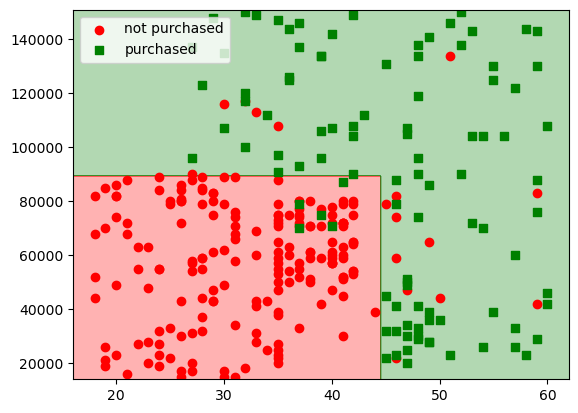

In [55]:
from matplotlib.colors import ListedColormap
class_color = ListedColormap(['red', 'green'])
y_dt = y_grid.reshape(X0.shape)
plt.contourf(X0, X1, y_dt, cmap=class_color, alpha=0.3)

X0_train = X_train[y_train==0,:]
X1_train= X_train[y_train ==1,:]

plt.scatter(X0_train[:,0], X0_train[:,1], color='red', label='not purchased')
plt.scatter(X1_train[:,0], X1_train[:,1], color='green', marker='s', label='purchased')
plt.legend()

[Text(0.6, 0.8333333333333334, 'x[0] <= 44.5\ngini = 0.447\nsamples = 300\nvalue = [199, 101]'),
 Text(0.4, 0.5, 'x[1] <= 89500.0\ngini = 0.275\nsamples = 225\nvalue = [188, 37]'),
 Text(0.5, 0.6666666666666667, 'True  '),
 Text(0.2, 0.16666666666666666, 'gini = 0.052\nsamples = 188\nvalue = [183, 5]'),
 Text(0.6, 0.16666666666666666, 'gini = 0.234\nsamples = 37\nvalue = [5, 32]'),
 Text(0.8, 0.5, 'gini = 0.25\nsamples = 75\nvalue = [11, 64]'),
 Text(0.7, 0.6666666666666667, '  False')]

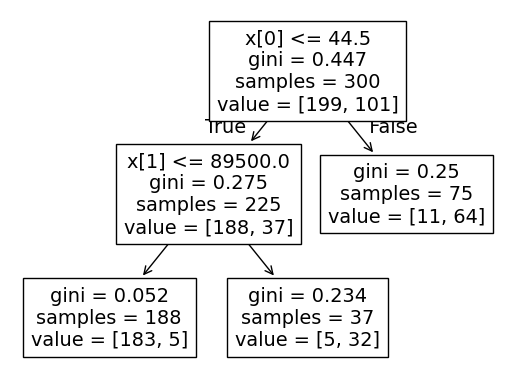

In [56]:
from sklearn.tree import plot_tree
plot_tree(dt)

In [59]:
print(dt.tree_.node_count)
print(dt.tree_.children_left)
print(dt.tree_.children_right)
print(dt.tree_.feature)

5
[ 1  2 -1 -1 -1]
[ 4  3 -1 -1 -1]
[ 0  1 -2 -2 -2]
